## Notebook contents
* Probability
* Bayes' theorem
* Normal (gaussian) distribution
* Binomial distribution

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

## Viz Helpers

In [2]:
# @title
# === DATA + PICTURE HELPERS — run this cell, then ignore it ========
COLORS = ["#2563eb", "#e07b39", "#3f9c7c"]

def load_uber(seed=11):
    "One month of Uber rides (simulated for teaching, not real company data)."
    rng = np.random.default_rng(seed)
    slots = 24 * 30                                    # 720 hourly slots in a month
    per_slot = rng.poisson(6, slots)                   # rides arriving each hour
    hour_slot = np.repeat(np.arange(slots), per_slot)
    n = len(hour_slot)
    hour = hour_slot % 24
    peak = np.isin(hour, [8, 9, 10, 17, 18, 19])
    trip = np.clip(rng.normal(24, 6, n), 4, None).round(1)
    fare = 45 + 11 * trip + rng.normal(0, 25, n)
    surge = rng.random(n) < 0.02
    fare = np.where(surge, fare * rng.uniform(2.0, 2.8, n), fare)
    cancelled = (rng.random(n) < np.where(peak, 0.20, 0.08)).astype(int)
    fraud = (rng.random(n) < 0.01).astype(int)
    flagged = (rng.random(n) < np.where(fraud == 1, 0.90, 0.05)).astype(int)
    return pd.DataFrame({
        "hour_slot":    hour_slot,                     # which hour of the month
        "hour":         hour,
        "is_peak":      peak.astype(int),
        "trip_minutes": trip,
        "fare":         fare.round(2),
        "surge":        surge.astype(int),
        "cancelled":    cancelled,
        "is_fraud":     fraud,
        "flagged":      flagged})

def _axes(title, xlabel, ylabel, size=(6, 4)):
    fig, ax = plt.subplots(figsize=size)
    ax.set_title(title, fontsize=11, loc="left")
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    ax.grid(True, axis="y", color="#e8e8e8"); ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    return ax

def show_hist(values, title, xlabel, marks=None, bins=40):
    ax = _axes(title, xlabel, "number of rides")
    ax.hist(values, bins=bins, color=COLORS[0], alpha=0.85)
    for i, (name, v) in enumerate((marks or {}).items()):
        ax.axvline(v, color=COLORS[i % 2 + 1], lw=2, ls="--")
        ax.annotate(f"{name} = {v:.1f}", (v, ax.get_ylim()[1] * (0.92 - 0.1 * i)),
                    xytext=(9, 0), textcoords="offset points",
                    color=COLORS[i % 2 + 1], fontsize=9)
    plt.show()

def show_bars(labels, values, title, ylabel, baseline=None, baseline_label=""):
    ax = _axes(title, "", ylabel)
    ax.bar([str(l) for l in labels], values, color=COLORS[0], width=0.55)
    for x, v in enumerate(values):
        ax.annotate(f"{v:.3f}", (x, v), xytext=(0, 4), textcoords="offset points",
                    ha="center", fontsize=9)
    if baseline is not None:
        ax.axhline(baseline, color=COLORS[1], lw=2, ls="--")
        ax.annotate(baseline_label, (len(values) - 1, baseline), xytext=(0, 9),
                    textcoords="offset points", ha="right", color=COLORS[1], fontsize=9)
    ax.margins(y=0.20); plt.show()

def show_fit(observed, predicted_x, predicted_p, title, xlabel):
    "Bars = what actually happened.  Dots = what the distribution predicts."
    ax = _axes(title, xlabel, "share of cases")
    seen = pd.Series(observed).value_counts(normalize=True).sort_index()
    ax.bar(seen.index, seen.values, color=COLORS[0], width=0.7, label="what we observed")
    ax.plot(predicted_x, predicted_p, "o", color=COLORS[1], ms=8,
            label="what the formula predicts")
    ax.legend(frameon=False, fontsize=9); plt.show()

## Probability

In [4]:
df = load_uber()
print("Uber ride file loaded:", len(df), "rides")

Uber ride file loaded: 4328 rides


In [12]:
df.shape

(4328, 9)

In [13]:
df.head()

,hour_slot,hour,is_peak,trip_minutes,fare,surge,cancelled,is_fraud,flagged
0,0,0,0,30.6,425.04,0,0,0,0
1,0,0,0,27.7,326.40,0,0,0,0
2,0,0,0,23.8,281.49,0,0,0,0
3,1,1,0,16.0,253.05,0,0,0,0
4,1,1,0,21.3,305.81,0,0,0,0


In [14]:
df.cancelled.sum()

np.int64(469)

In [15]:
print("cancelled        :", df["cancelled"].sum())
print("flagged by system:", df["flagged"].sum())
print("actually fraud   :", df["is_fraud"].sum())

cancelled        : 469
flagged by system: 270
actually fraud   : 44


In [17]:
# A - a ride is cancelled
# P(A)

print(f'P(cancelled) = {df.cancelled.mean():.3f}')

P(cancelled) = 0.108


In [36]:
peak_rides = (df[df.is_peak==1])

print("rush-hour rides          :", len(peak_rides))

# similar to - round(peak_rides.cancelled.sum()/len(peak_rides), 3)
print(f'P(cancelled | peak hour): {peak_rides.cancelled.mean():.3f}')

rush-hour rides          : 1064
P(cancelled | peak hour): 0.178


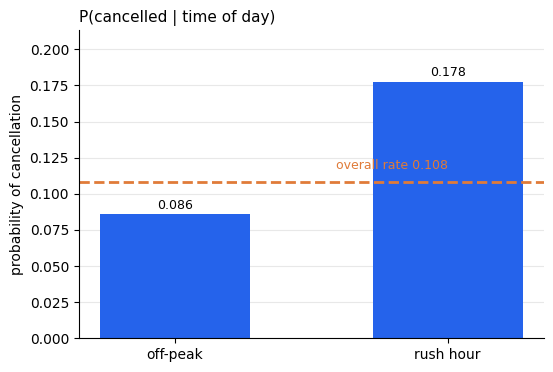

In [38]:
by_peak = df.groupby('is_peak')['cancelled'].mean()

show_bars(["off-peak", "rush hour"], by_peak.values,
          "P(cancelled | time of day)", "probability of cancellation",
          baseline=df["cancelled"].mean(), baseline_label="overall rate 0.108")

### Usage of commutative law of probability (AND)
* P(ride is cancelled | peak hour) = P(peak hour | ride is cancelled )
* P(A|B) = P(B|A)

In [45]:
# P(peak hour | ride is cancelled )

print(round(df[df.cancelled == 1]['is_peak'].mean(), 3))

0.403


In [46]:
print(f'P(Cancelled | peak) = {round(df[df.is_peak == 1]['cancelled'].mean(), 3)}')
print(f'P(peak | cancelled) = {round(df[df.cancelled == 1]['is_peak'].mean(), 3)}')

P(Cancelled | peak) = 0.178
P(peak | cancelled) = 0.403


## Bayes Theorem
- The system flagged 270 rides. Out of the flagged rides **how many are really fraud?**

In [51]:
round(df.is_fraud.mean(), 4)

np.float64(0.0102)

In [53]:
# P( fraud | flagged)

prior = df.is_fraud.mean()                              # how common fraud is
hit_rate = df[df.is_fraud == 1]['flagged'].mean()       # catches real fraud
false_alarm = df[df.is_fraud == 0]['flagged'].mean()   # alerts on honest rides

print("P(fraud)              =", round(prior, 4))
print("P(flagged | fraud)    =", round(hit_rate, 3))
print("P(flagged | no fraud) =", round(false_alarm, 3))

P(fraud)              = 0.0102
P(flagged | fraud)    = 0.909
P(flagged | no fraud) = 0.054


In [54]:
evidence = hit_rate * prior + false_alarm * (1-prior)
print(f'P(flagged) = {round(evidence, 4)}')

P(flagged) = 0.0624


In [55]:
posterior = hit_rate * prior / evidence
print(f'P(fraud | flagged) = {posterior:.3f}')

P(fraud | flagged) = 0.148


| Term | Name | Meaning here |
|---|---|---|
| `P(fraud)` | **prior** | how common fraud is before you look at any alert |
| `P(flagged \| fraud)` | **likelihood** | how good the system is at catching real fraud |
| `P(flagged)` | **evidence** | how often the system alerts at all |
| `P(fraud \| flagged)` | **posterior** | **what we actually want to know** |

## Applications of Bayes' theorem

* Health care example
  * A disease affects 1% of the population. A test has a 5% false positive rate. P(positve|not infected) = 0.05 and is 95%  correctly identifies. P(positve|infected) = 0.95 If a patient tests positive, what is the probability they actually have the disease?



* ...similarly
| Where you meet this | The updated belief |
|---|---|
| Spam filters | P(spam \| contains "winner") |
| Medical tests | P(disease \| positive result) |
| Fraud detection | P(fraud \| flagged) — today |
| Naive Bayes classifiers | Bayes applied to many clues at once |

## Distributions

## Normal distribution
* Also known as GAUSSIAN distribution or BELL curve.
* Symmetrical on both right and left to the mean (barely or not skewed).
* Mean and median are very close or almost same.
* The popular empirical rule (also called the 68-95-99.7 rule or three-sigma rule) is a statistical guideline that states how data values are spread out around the mean in a normal distribution (bell curve).

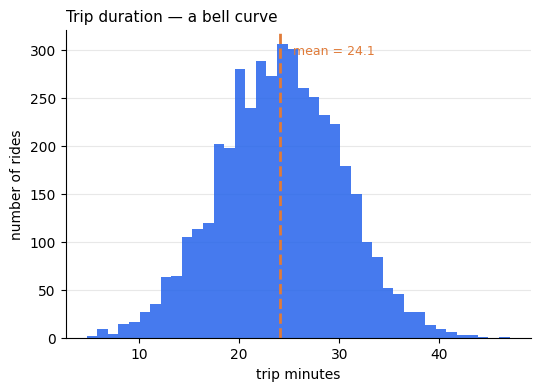

In [59]:
show_hist(df["trip_minutes"], "Trip duration — a bell curve", "trip minutes",
          marks={"mean": df["trip_minutes"].mean()})

In [69]:
# checking skewness of fare column
round(df.fare.skew(), 3)

np.float64(2.639)

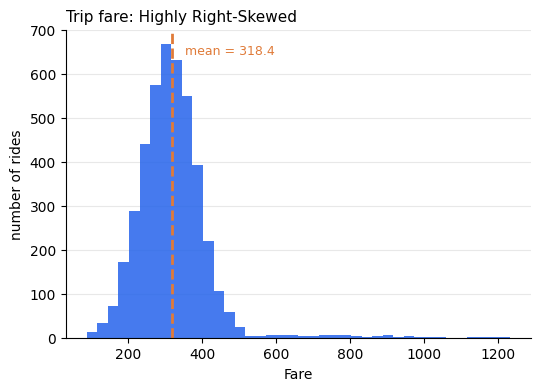

In [72]:
# fare
show_hist(df.fare, 'Trip fare: Highly Right-Skewed', 'Fare',
          marks = {'mean':df.fare.mean()})

In [73]:
# Trip minutes
trips = df.trip_minutes
mu = df.trip_minutes.mean()
sig = df.trip_minutes.std()

In [89]:
# Trips ±1 std
round((((trips > (mu -1*sig)) & (trips < (mu +1*sig))).mean()), 3)

np.float64(0.683)

In [90]:
# Trips ±2 std
round((((trips > (mu -2*sig)) & (trips < (mu +2*sig))).mean()), 3)

np.float64(0.953)

In [91]:
# Trips ±3 std
round((((trips > (mu -3*sig)) & (trips < (mu +3*sig))).mean()), 3)

np.float64(0.998)

In [115]:
# how many rides or trips can one driver finish in 30 minutes?

round(stats.norm.cdf(30, loc = mu, scale=sig), 4)

np.float64(0.833)

In [112]:
# Cross checking mean and standard dev
df.mean(), "-----------------------------------" , df.std()

(hour_slot       367.066774
 hour             11.364372
 is_peak           0.245841
 trip_minutes     24.120702
 fare            318.445580
 surge             0.018946
 cancelled         0.108364
 is_fraud          0.010166
 flagged           0.062384
 dtype: float64,
 '-----------------------------------',
 hour_slot       207.678187
 hour              6.901238
 is_peak           0.430634
 trip_minutes      6.084734
 fare             97.912484
 surge             0.136351
 cancelled         0.310876
 is_fraud          0.100326
 flagged           0.241880
 dtype: float64)

In [117]:
# how many rides or trips can one driver finish in 32 minutes?
round(stats.norm.cdf(32, loc = mu, scale=sig), 4) # Cumulative distribution function

np.float64(0.9023)

In [119]:
# How many rides or trips take more than 38 minutes to complete?
round(1 - stats.norm.cdf(38, loc = mu, scale=sig), 3) # Around 1%

np.float64(0.011)

In [132]:
# 95% percent of trips finish under what time?
# ppf is inverse of cdf

slow_trip  = round(stats.norm.ppf(0.95, loc=mu, scale=sig), 3) # percent point function
slow_trip # around 34 minutes

np.float64(34.129)

In [133]:
# How many rides can one driver finish in 60 minutes?

per_driver = 60/slow_trip

print("a slow trip (95th percentile):", round(slow_trip, 1), "minutes")
print("rides one driver can clear   :", round(per_driver, 2), "per hour")

a slow trip (95th percentile): 34.1 minutes
rides one driver can clear   : 1.76 per hour


### Findings
* 95% of drivers completes 1.76 trips per hour

In [139]:
# Similarly...99 trips done under what time?
round(stats.norm.ppf(0.99999, loc = mu, scale = sig), 3) # approximately 49 or 50 minutes

np.float64(50.071)

## Binomial distribution
- A driver takes **20 ride requests** in a shift. How many get cancelled?

In [144]:
p_cancel = df.cancelled.mean()
n_rides = 20

print(f'Probability of cancelled rides = {(p_cancel):.3f}')
print(f"P(cancel) per ride   : {round(p_cancel, 3)}")
print(f'P(exactly 3 cancel)  : {stats.binom.pmf(3, n_rides, p_cancel):.3f}')
print(f'P(exactly 2 cancel)  : {stats.binom.pmf(2, n_rides, p_cancel):.3f}')
print(f'P(exactly 1 cancel)  : {stats.binom.pmf(1, n_rides, p_cancel):.3f}')

Probability of cancelled rides = 0.108
P(cancel) per ride   : 0.108
P(exactly 3 cancel)  : 0.206
P(exactly 2 cancel)  : 0.283
P(exactly 1 cancel)  : 0.245


In [151]:
# Similarly...what is the probability of 2 or less trips getting cancelled?
# Approx 62% chances that cancelled rides are under 2 or less.

print(f'P(Cancel <=2) = {stats.binom.cdf(2, n_rides, p_cancel):.3f}') # for that we will use the cumulative distribution function of a binomial distribution

P(Cancel <=2) = 0.629
